In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from forestgap import Proximity
from aeon.classification.sklearn import RotationForestClassifier
from forestgap.manifold import phate
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns
import numpy as np

# Convert treeData to a pandas DataFrame
treeData = pd.read_csv("../datasets/treeData.csv")
treeData = pd.DataFrame(treeData)
X = treeData.drop(columns=["branch"])
y = treeData["branch"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    shuffle=True
)

In [2]:
%matplotlib inline

In [3]:
rf = RotationForestClassifier(n_estimators=100, random_state=42)
rfProx = Proximity(rf, relation = 'rfgap')

In [4]:
rfProx.fit(X_train, y_train)

,n_estimators,100
,min_group,3
,max_group,3
,remove_proportion,0.5
,base_estimator,None
,pca_solver,'auto'
,time_limit_in_minutes,0.0
,contract_max_n_estimators,500
,n_jobs,1
,random_state,42


In [5]:
prox_oob_matches = (rfProx.oob_decision_function_.argmax(axis=1) == rfProx.prox_predict().argmax(axis=1))


In [6]:
np.where(~prox_oob_matches)

(array([], dtype=int64),)

In [7]:
print(rfProx.oob_decision_function_[273, :])
print(rfProx.prox_predict()[273])

[0.         0.         0.         0.05882353 0.         0.02941176
 0.02941176 0.88235294 0.         0.        ]
[0.         0.         0.         0.05882353 0.         0.02941176
 0.02941176 0.88235295 0.         0.        ]


In [8]:
print(rfProx.oob_decision_function_[707, :])
print(rfProx.prox_predict()[707])

[0.         0.2962963  0.         0.14814815 0.55555556 0.
 0.         0.         0.         0.        ]
[0.         0.2962963  0.         0.14814815 0.55555555 0.
 0.         0.         0.         0.        ]


In [9]:
print(rfProx.oob_decision_function_[793, :])
print(rfProx.prox_predict()[793])

[0.    0.    0.425 0.    0.    0.    0.    0.    0.5   0.075]
[0.    0.    0.425 0.    0.    0.    0.    0.    0.5   0.075]


In [10]:
emb = phate.fit_phate_from_forest(rfProx)

Calculating PHATE...
  Running PHATE on precomputed affinity matrix with 1008 observations.
  Calculating graph and diffusion operator...
  Calculating optimal t...
    Automatically selected t = 12
  Calculated optimal t in 0.41 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.08 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by -2.5% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 1.19 seconds.
Calculated PHATE in 1.70 seconds.


<Axes: >

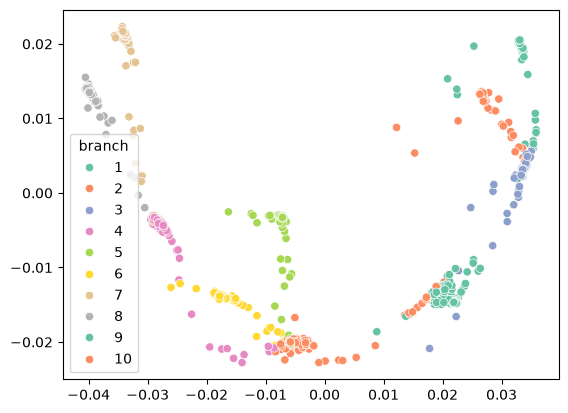

In [11]:
matches_mask = rfProx.oob_decision_function_.argmax(axis=1) == rfProx.prox_predict().argmax(axis=1)

sns.scatterplot(x=emb[matches_mask, 0], y=emb[matches_mask, 1], hue=y_train[matches_mask], palette="Set2")
sns.scatterplot(x=emb[~matches_mask, 0], y=emb[~matches_mask, 1], color="red", marker="X", s=200, legend=False)